# ULTIMATE: targeted population-failure diagnosis and positive forward model
## tl;dr
**NO-GO for a robust dust-geometry claim using the current pipeline.** The catastrophic control is reproduced and explained by a misweighted population field plus dust-colour overlap. A positive multiplicative model improves contrast fits but fails physical absolute-colour tests and challenging held-out controls. Sparse apertures also discard important spatial information; these results do **not** establish a universal impossibility of broadband imaging.

This notebook executes numerical checks, reproduces the named Gaussian failure, fits the positive model to measured fluxes and analyses the completed bounded pilot. It does not repeat the old full experiment. The pilot was executed from the supplied code; its complete logs, per-draw results, thresholds and optimizer flags are retained. Set `RECOMPUTE_PILOT=True` only to rerun that focused pilot, not the previous grid.


## Context & Methods
Positive luminosity × convex mixtures of independent training-region source SEDs × positive attenuation, with native band-dependent PSFs. Actual DR1 griz/JHKs retain their rest-band meaning. z=.3 is conditional matched-rest-band degradation, not exact observer-frame ULTIMATE photometry.

### Key assumptions
Training region x<-4kpc; target clear SEDs never enter fitting. Templates/priors/spatial fields were frozen before new held-out patterns. Uniform versus varying E uses the same population model. Both absolute linear fluxes and normalized contrasts are examined. Luminosity is nuisance. Posterior checks use a local Laplace approximation and do not certify global/multimodal inference. Failed physical gate prevents a large evaluation or validated GLAO power forecast.


In [1]:
import os,sys
from pathlib import Path
os.environ['MPLCONFIGDIR']='/tmp/ultimate-mpl'
os.environ['OPENBLAS_NUM_THREADS']='1'
sys.dont_write_bytecode=True
O=Path('/home/bahareh/ULTIMATE/analysis_results/multiplicative_diagnosis_20261026')
sys.path.insert(0,str(O))
import numpy as np,pandas as pd
import diagnose,physical_model,make_report,degeneracy_bound,aperture_information
from IPython.display import display,Image,Markdown
print(sys.executable)
assert '/envs/phd/' in sys.executable


/home/bahareh/miniforge3/envs/phd/bin/python


## Data and numerical checks
The existing local DR1 products and prior instrument model are read-only dependencies. Tests cover positivity, nesting, analytic gradients, training separation, uniform and structured adjoint projection, and exact loss of uniform-E information under normalization.

In [2]:
import unittest,test_physical
result=unittest.TextTestRunner(verbosity=1).run(unittest.defaultTestLoader.loadTestsFromModule(test_physical))
assert result.wasSuccessful()


.

.

.

.

.

.

----------------------------------------------------------------------
Ran 6 tests in 1.278s

OK


### Reproduce only the named catastrophic control
The following is a targeted reproduction with its original seed, not a rerun of the previous grid. Covariance/spatial changes are diagnostic ablations, not adopted priors.

In [3]:
mechanism=diagnose.run()
display(mechanism[['strategy','mode','variant','noise_free_statistic','reproduced_FPR']].round(4))


strategy   mode                         variant  noise_free_statistic  prior_predictive_q_null  prior_predictive_q_variable  dimension  posterior_predictive_null  posterior_predictive_variable  reproduced_FPR   ci_low  ci_high  threshold  noise_free_score_above_threshold
 matched seeing                        baseline             85.447266               286.048090                   148.582318         98                      0.918                          0.592           0.984 0.968718 0.993068  69.587214                              True
 matched seeing               population_scale2            -22.386560                90.870680                    66.654505         98                      0.980                          0.887           0.984 0.968718 0.993068  69.587214                             False
 matched seeing explicit_anchor_population_mode            -41.787527                51.778271                    42.057897         98                      0.985                       

,strategy,mode,variant,noise_free_statistic,reproduced_FPR
0,matched,seeing,baseline,85.4473,0.984
1,matched,seeing,population_scale2,-22.3866,0.984
2,matched,seeing,explicit_anchor_population_mode,-41.7875,0.984
3,matched,seeing,smaller_spatial_RBF,-42.6004,0.984
4,matched,glao,baseline,79.7517,0.960
5,matched,glao,population_scale2,-27.5176,0.960
6,matched,glao,explicit_anchor_population_mode,-43.7096,0.960
7,matched,glao,smaller_spatial_RBF,-44.9547,0.960
8,native,seeing,baseline,-21.8047,0.124
9,native,seeing,population_scale2,-19.5049,0.124


### Execute the improved model using measured fluxes
These saved observations were generated in the development experiment. Fitting accepts only their noisy fluxes and photometric covariance; no target intrinsic SED is provided.

In [4]:
model=physical_model.ForwardModel('seeing')
d=np.load(O/'development_fits.npz')
checks=[]
for normalized,kind in [(False,'absolute'),(True,'contrasts')]:
    label='problem_anchor_one_noise_'+kind
    fit=model.fit(d[label+'_observed'],d[label+'_noise_cov'],normalized=normalized)
    checks.append({'likelihood':kind,'chi2':fit['chi2'],'local_predictive_p':fit['ppp'],'optimizer_success':fit['success']})
display(pd.DataFrame(checks))


,likelihood,chi2,local_predictive_p,optimizer_success
0,absolute,812.149853,0.000,True
1,contrasts,75.598474,0.202,True


### Bounded held-out pilot and gate
The raw physical gate failed. No large evaluation follows. The executed pilot has19 known-family calibration draws, one absolute-colour and three contrast draws per scene. Separate new spatial PC1+PC3 and training-SED patch scenarios are retained individually. Small-sample intervals are insufficient to certify a5% false-positive rate. The diagnostic MAP statistic includes prior penalties; it is not a Bayes factor.

In [5]:
RECOMPUTE_PILOT=False
if RECOMPUTE_PILOT:
    import pilot
    pilot.run()
print((O/'development_gate.json').read_text())
display(pd.read_csv(O/'heldout_pilot_rates.csv'))


{
  "physical_null_gate_passed": false,
  "criteria": "optimizer success and local posterior predictive p>=.01 on both prespecified native seeing nulls; effective-dof chi-square tails descriptive only",
  "larger_evaluation_permitted": false,
  "elapsed_seconds": 57.33021545410156
}


,population,screen,likelihood,n,rejections,rate,ci_low,ci_high,adequate_null_fraction,adequate_alternative_fraction,all_optimizers_success
0,DR1,clear,absolute,1,1,1.000000,0.025000,1.000000,0.000000,0.000000,True
1,DR1,clear,contrasts,3,2,0.666667,0.094299,0.991596,1.000000,1.000000,True
2,DR1,patchy,absolute,1,1,1.000000,0.025000,1.000000,0.000000,0.000000,True
3,DR1,patchy,contrasts,3,3,1.000000,0.292402,1.000000,0.333333,1.000000,False
4,DR1,smooth,absolute,1,1,1.000000,0.025000,1.000000,0.000000,0.000000,False
5,DR1,smooth,contrasts,3,3,1.000000,0.292402,1.000000,0.000000,0.000000,False
6,DR1,uniform,absolute,1,1,1.000000,0.025000,1.000000,0.000000,0.000000,False
7,DR1,uniform,contrasts,3,1,0.333333,0.008404,0.905701,1.000000,0.666667,False
8,SKIRT,original,absolute,1,1,1.000000,0.025000,1.000000,0.000000,0.000000,True
9,SKIRT,original,contrasts,3,3,1.000000,0.292402,1.000000,0.000000,0.333333,False


## Results: spatial information and identifiability
The positive counterexample is ambiguous in the sparse apertures but distinguishable in the full evaluation rectangle. Known-pair classification bounds are optimistic and conditional, not nuisance-marginalized recovery rates. Full-image adequacy remains unvalidated.

In [6]:
display(degeneracy_bound.run())
display(aperture_information.run())
display(pd.read_csv(O/'native_adequacy_sensitivity.csv').query('field=="fine" and bin_kpc==1.5 and variable==False')[['mode','scene','chi2','ppp','success']])


  mode  mean_separation_squared  optimal_simple_hypothesis_power_at_FPR05  optimal_equal_prior_error  E_rms_difference  intrinsic_g_Ks_colour_rms_difference_mag  illustrative_independent_coherent_colour_mode_sigma_for_80pct_power_mag
seeing                 0.103464                                  0.092885                   0.436114          0.019203                                  0.052726                                                                 0.021385
  glao                 0.080998                                  0.086875                   0.443421          0.019203                                  0.052726                                                                 0.021346


,mode,mean_separation_squared,optimal_simple_hypothesis_power_at_FPR05,optimal_equal_prior_error,E_rms_difference,intrinsic_g_Ks_colour_rms_difference_mag,illustrative_independent_coherent_colour_mode_sigma_for_80pct_power_mag
0,seeing,0.103464,0.092885,0.436114,0.019203,0.052726,0.021385
1,glao,0.080998,0.086875,0.443421,0.019203,0.052726,0.021346


  mode                             data  n_spatial_pixels  squared_mean_separation  optimal_pair_power_at_FPR05
seeing pixels_inside_original_apertures               160                 1.064104                     0.269839
seeing      evaluation_rectangle_pixels               720                33.129397                     0.999980
seeing               whole_frame_pixels             15876              1713.514935                     1.000000
  glao pixels_inside_original_apertures               160                 1.061923                     0.269490
  glao      evaluation_rectangle_pixels               720                33.656280                     0.999984
  glao               whole_frame_pixels             15876              1725.655376                     1.000000
seeing            original_15_apertures                15                 0.103464                     0.092885
  glao            original_15_apertures                15                 0.080998                     0

,mode,data,n_spatial_pixels,squared_mean_separation,optimal_pair_power_at_FPR05
0,seeing,pixels_inside_original_apertures,160,1.064104,0.269839
1,seeing,evaluation_rectangle_pixels,720,33.129397,0.999980
2,seeing,whole_frame_pixels,15876,1713.514935,1.000000
3,glao,pixels_inside_original_apertures,160,1.061923,0.269490
4,glao,evaluation_rectangle_pixels,720,33.656280,0.999984
5,glao,whole_frame_pixels,15876,1725.655376,1.000000
6,seeing,original_15_apertures,15,0.103464,0.092885
7,glao,original_15_apertures,15,0.080998,0.086875


,mode,scene,chi2,ppp,success
0,seeing,uniform,73.612902,0.241,False
2,seeing,anchor,62.168936,0.496,False
12,glao,uniform,49.251604,0.583,True
14,glao,anchor,154.982123,0.000,False


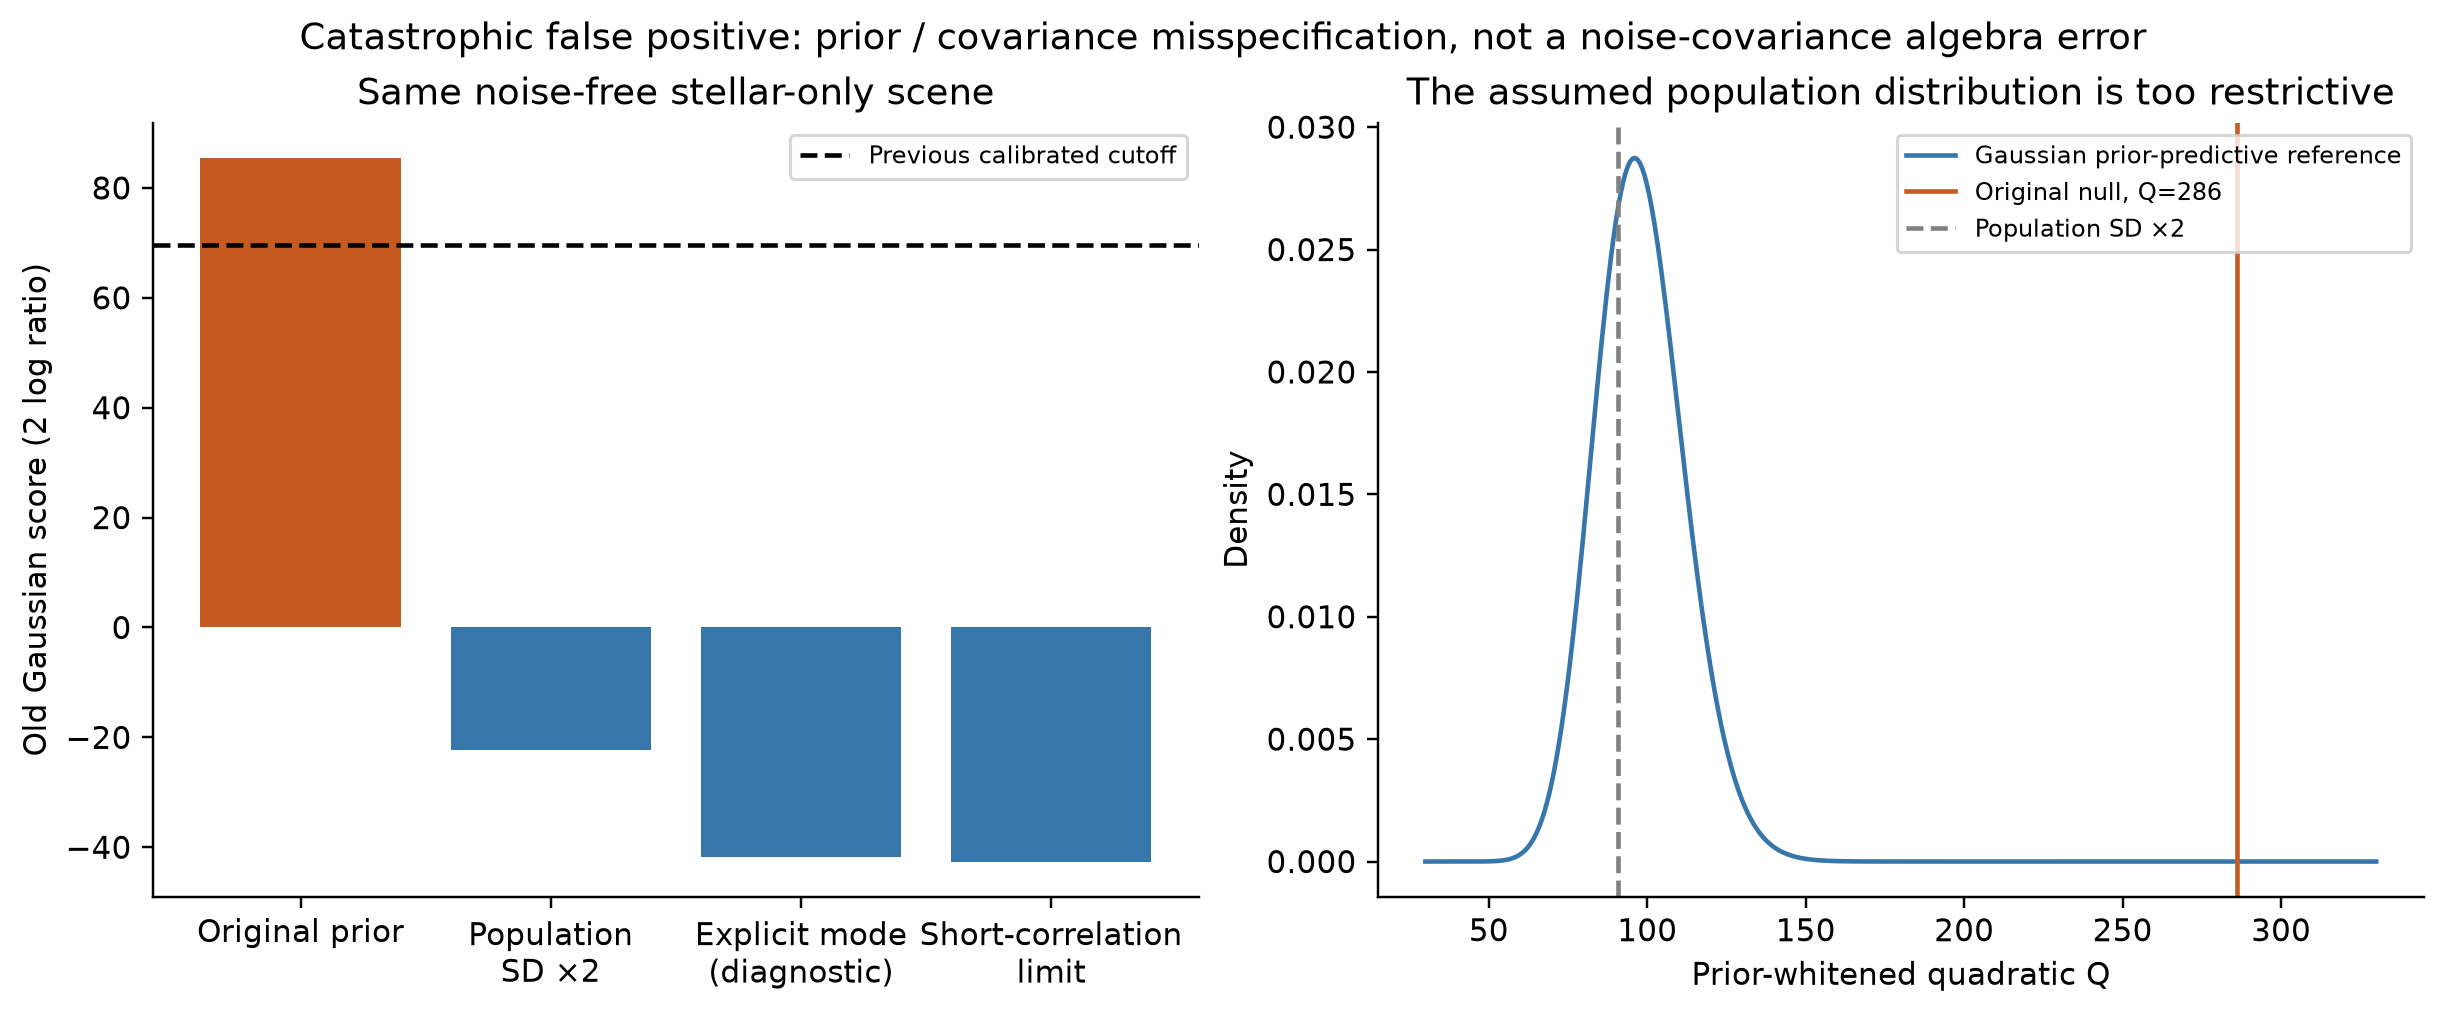

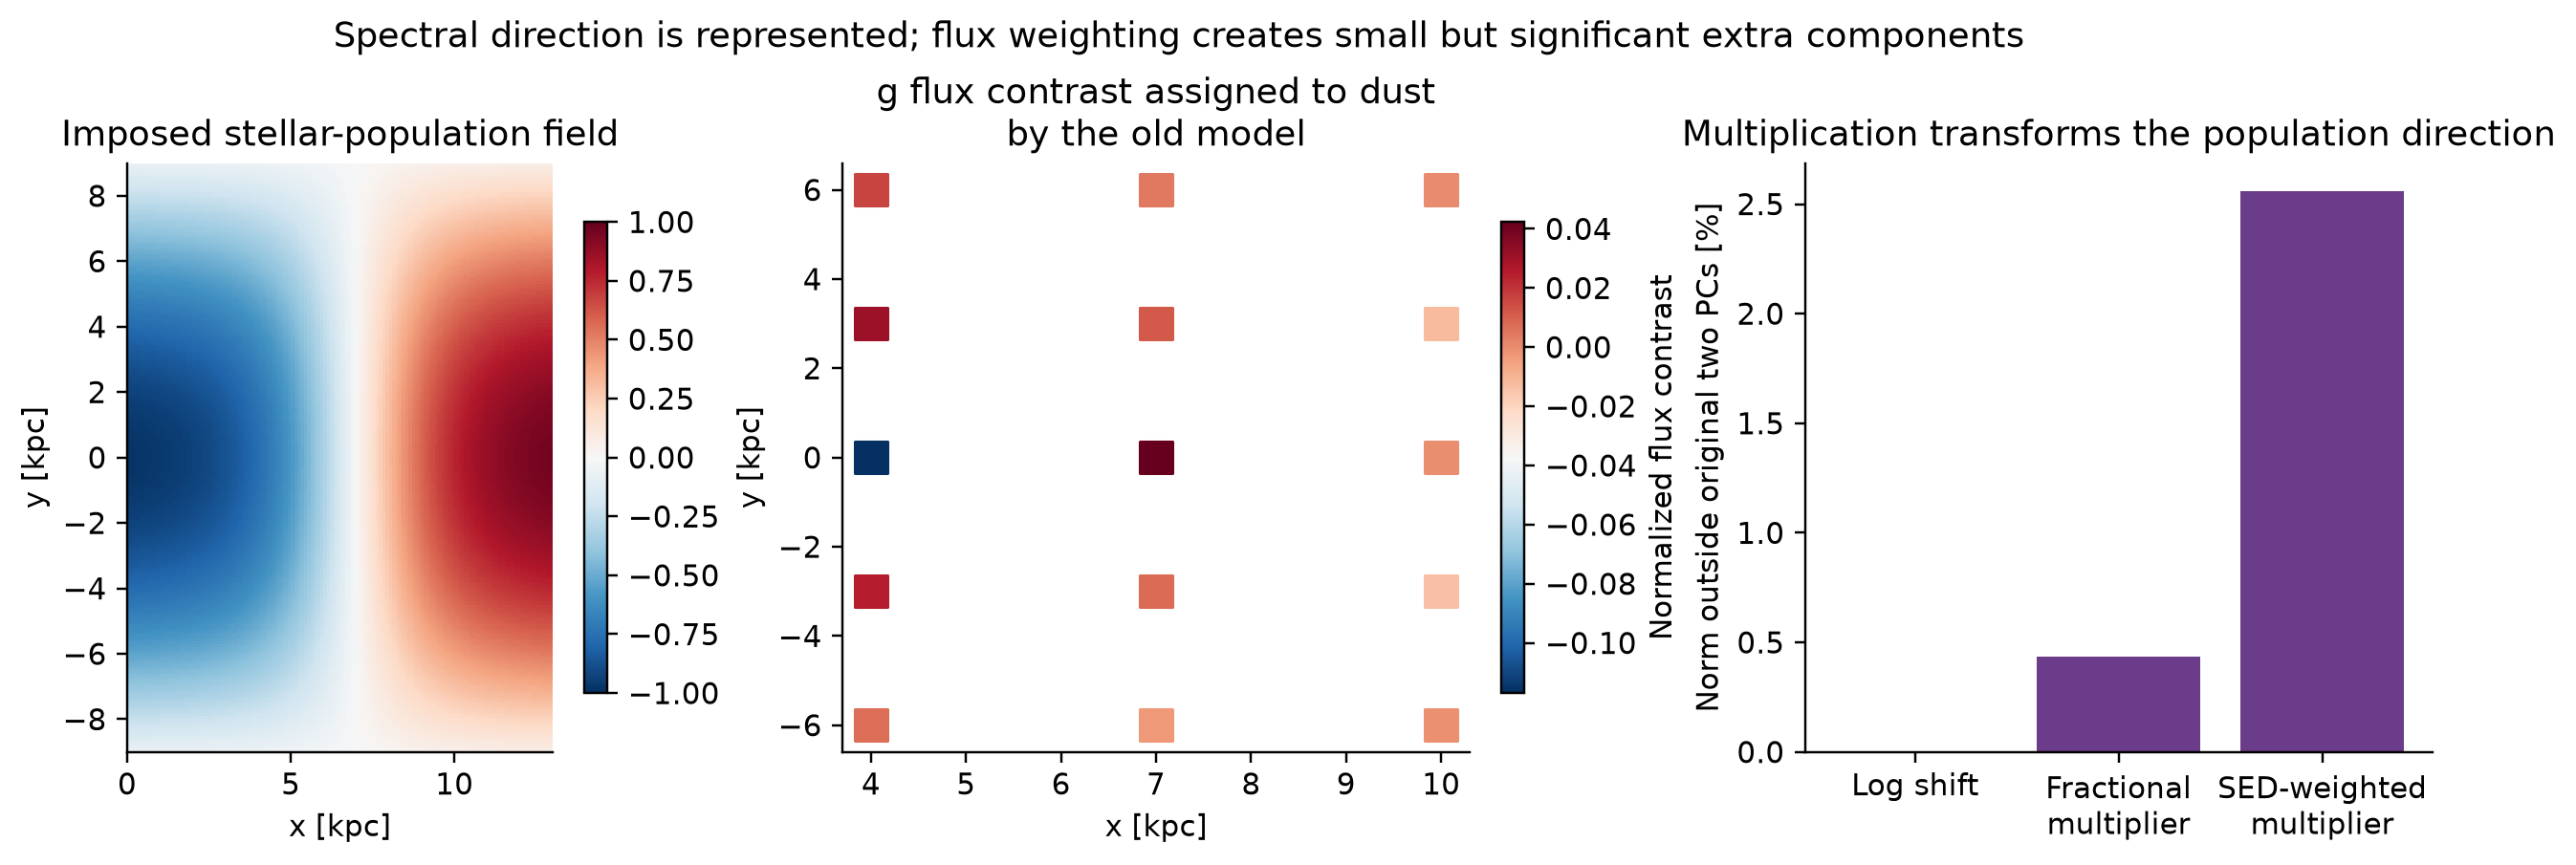

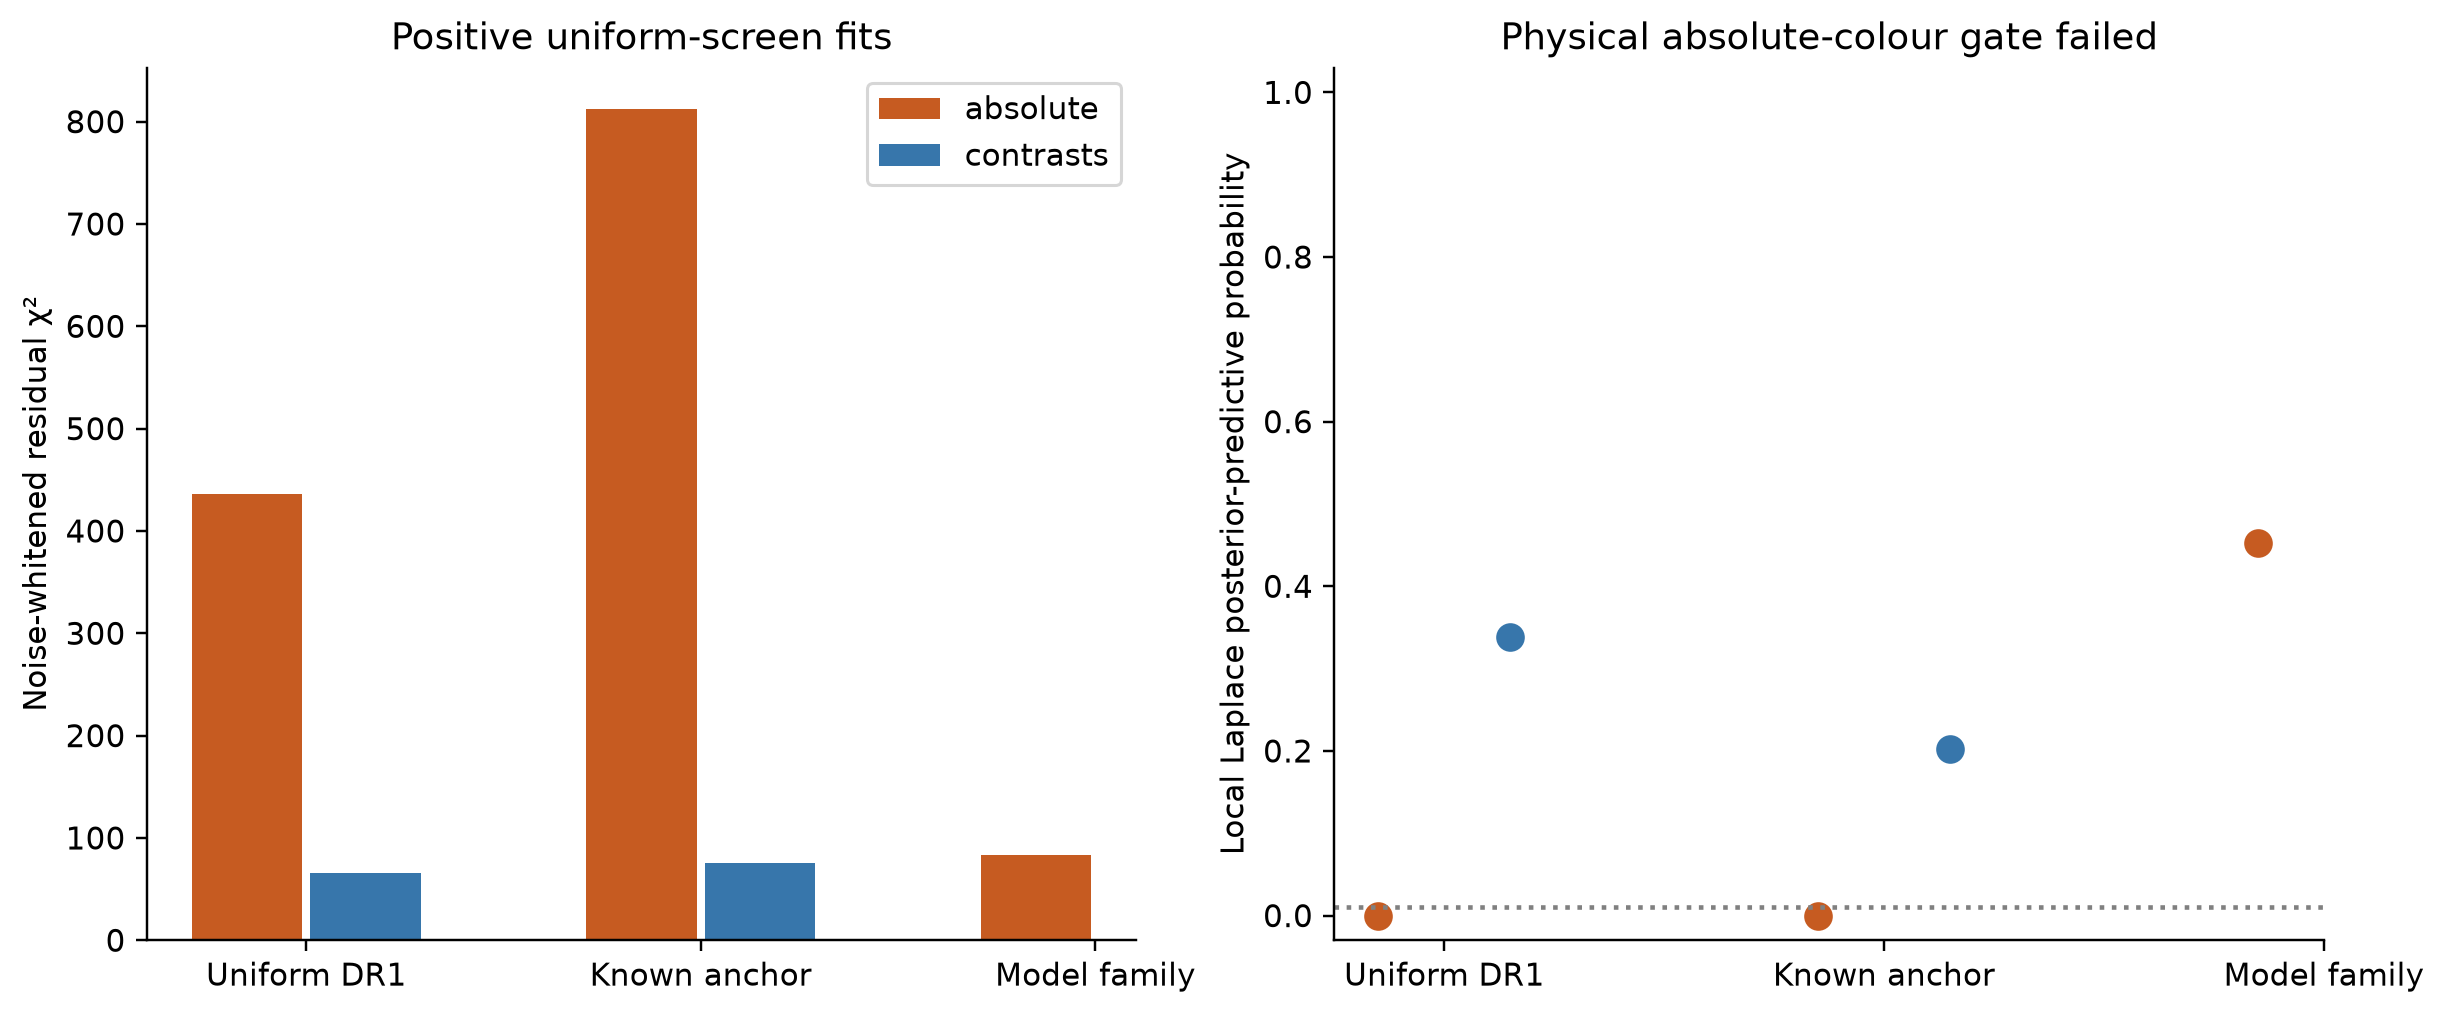

In [7]:
paths=make_report.run()
for path in paths[:3]:
    display(Image(filename=str(path)))


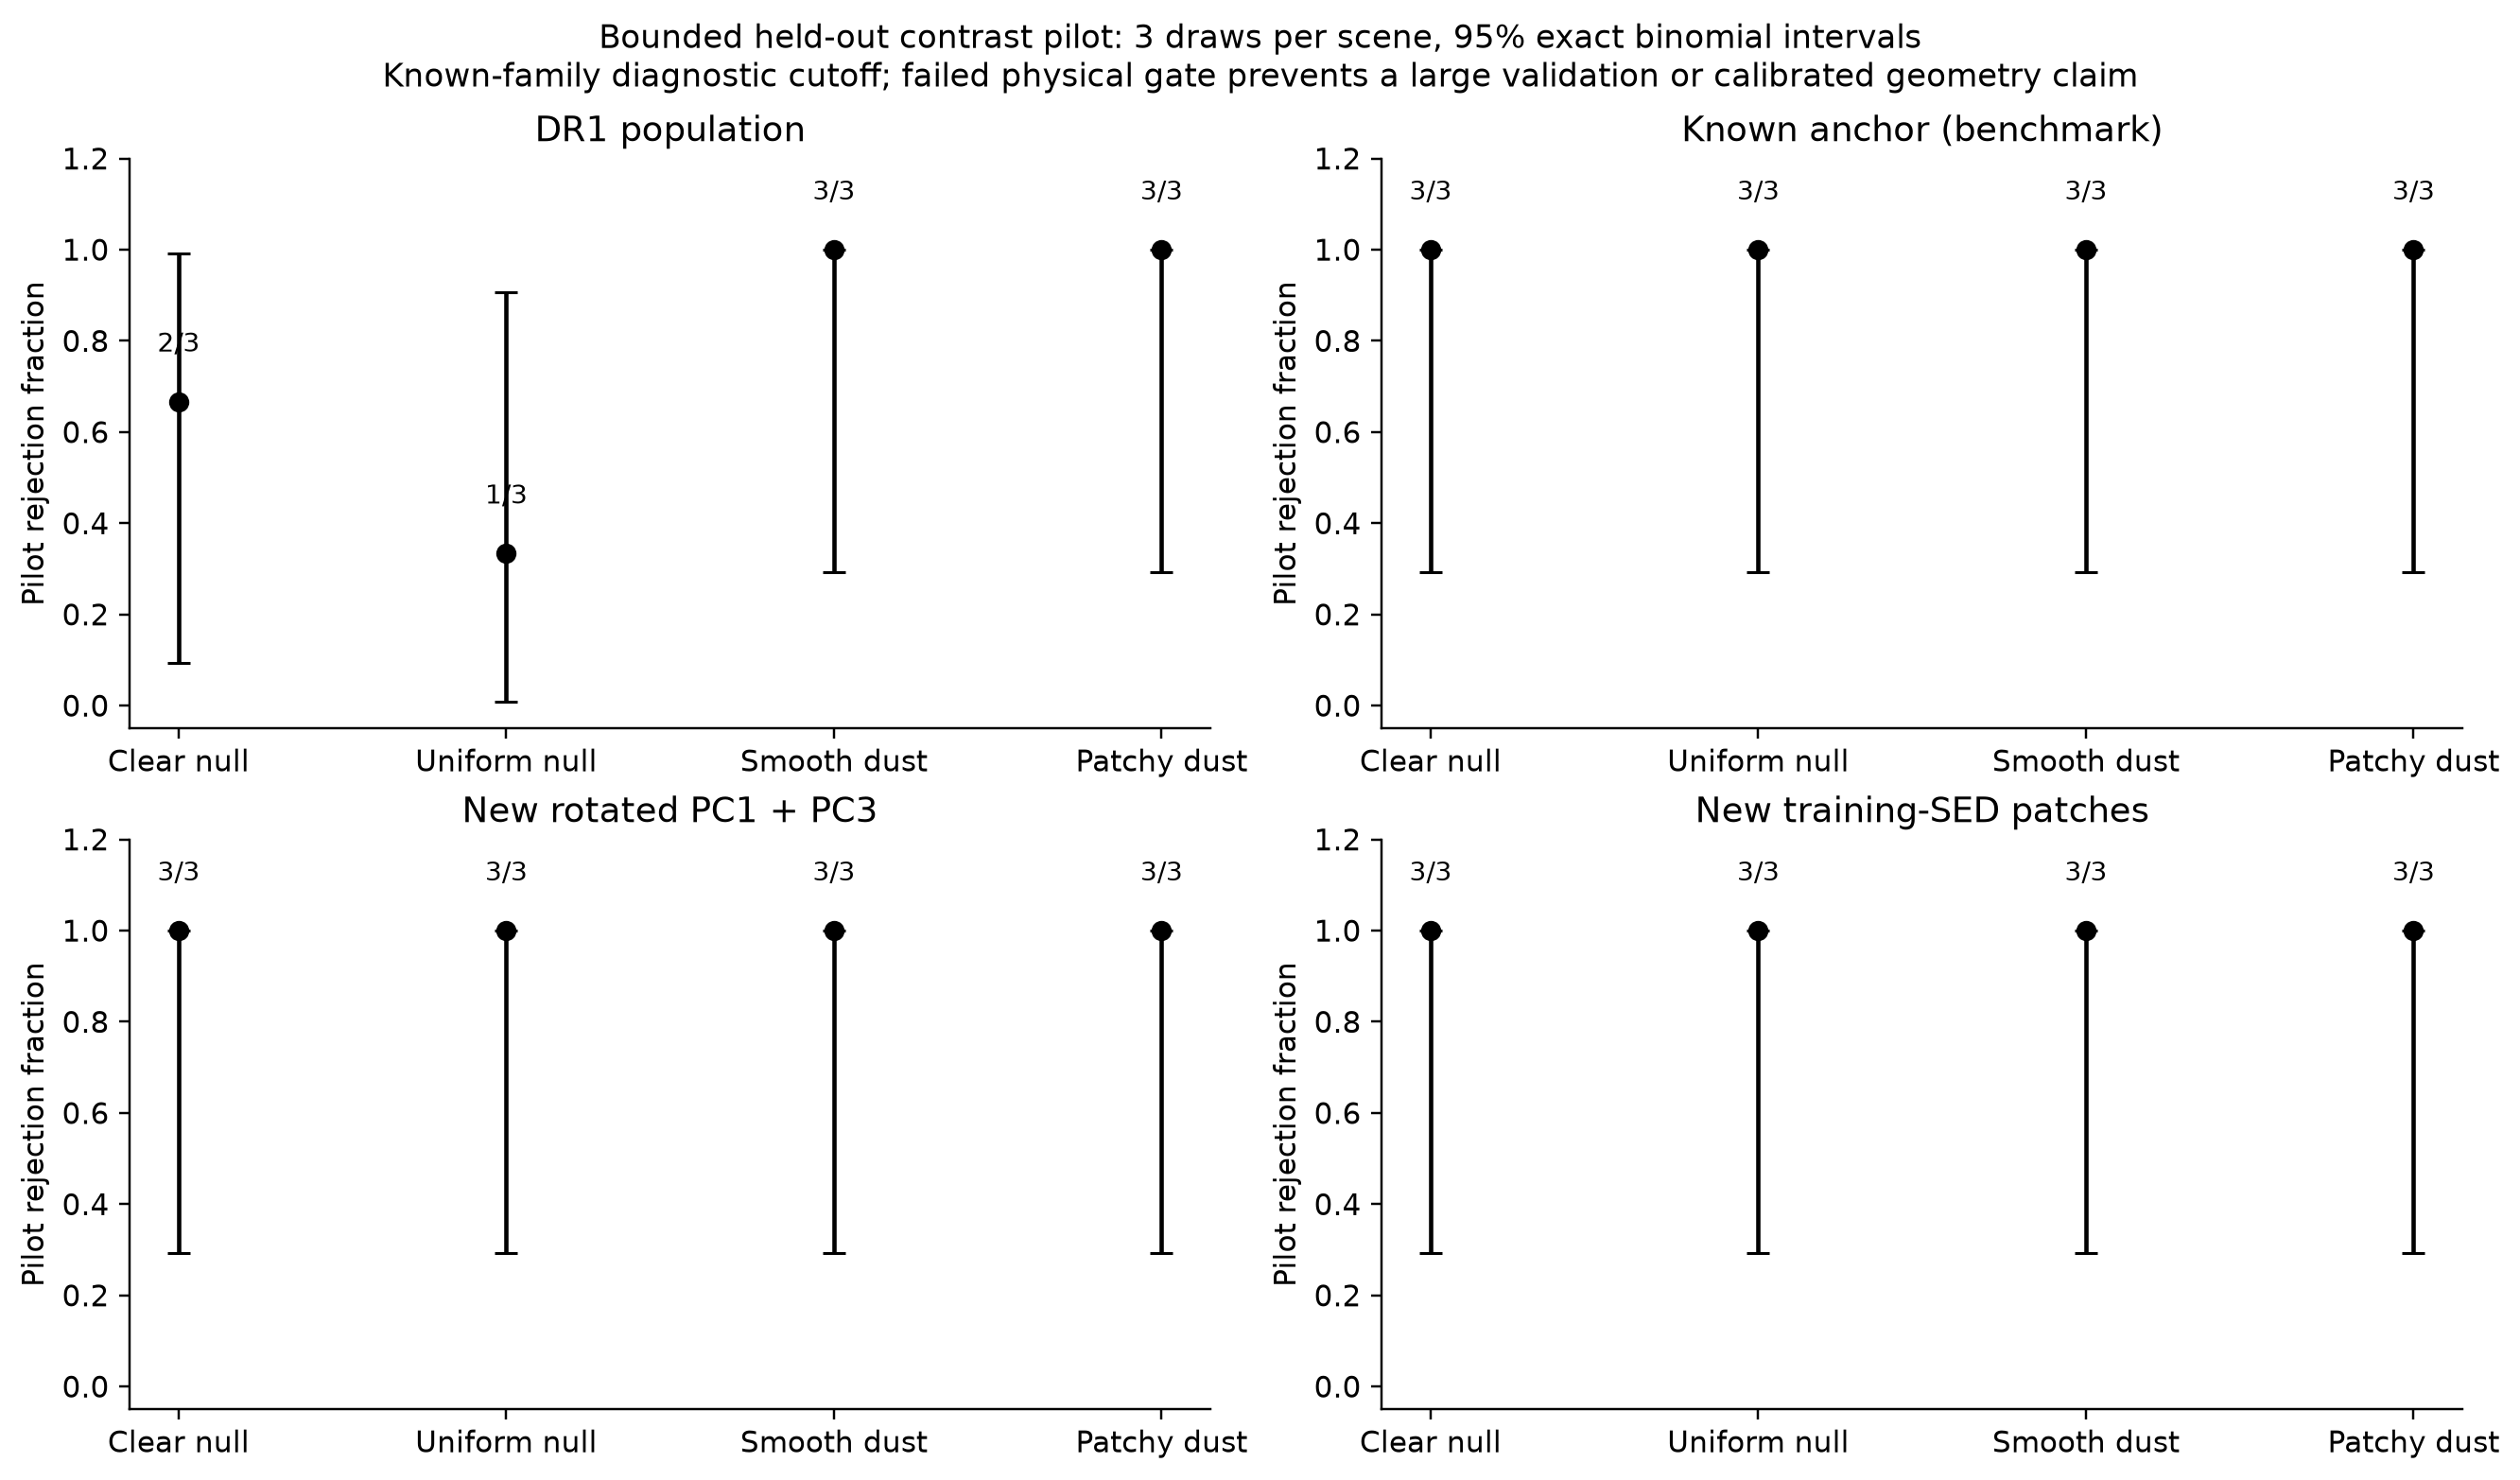

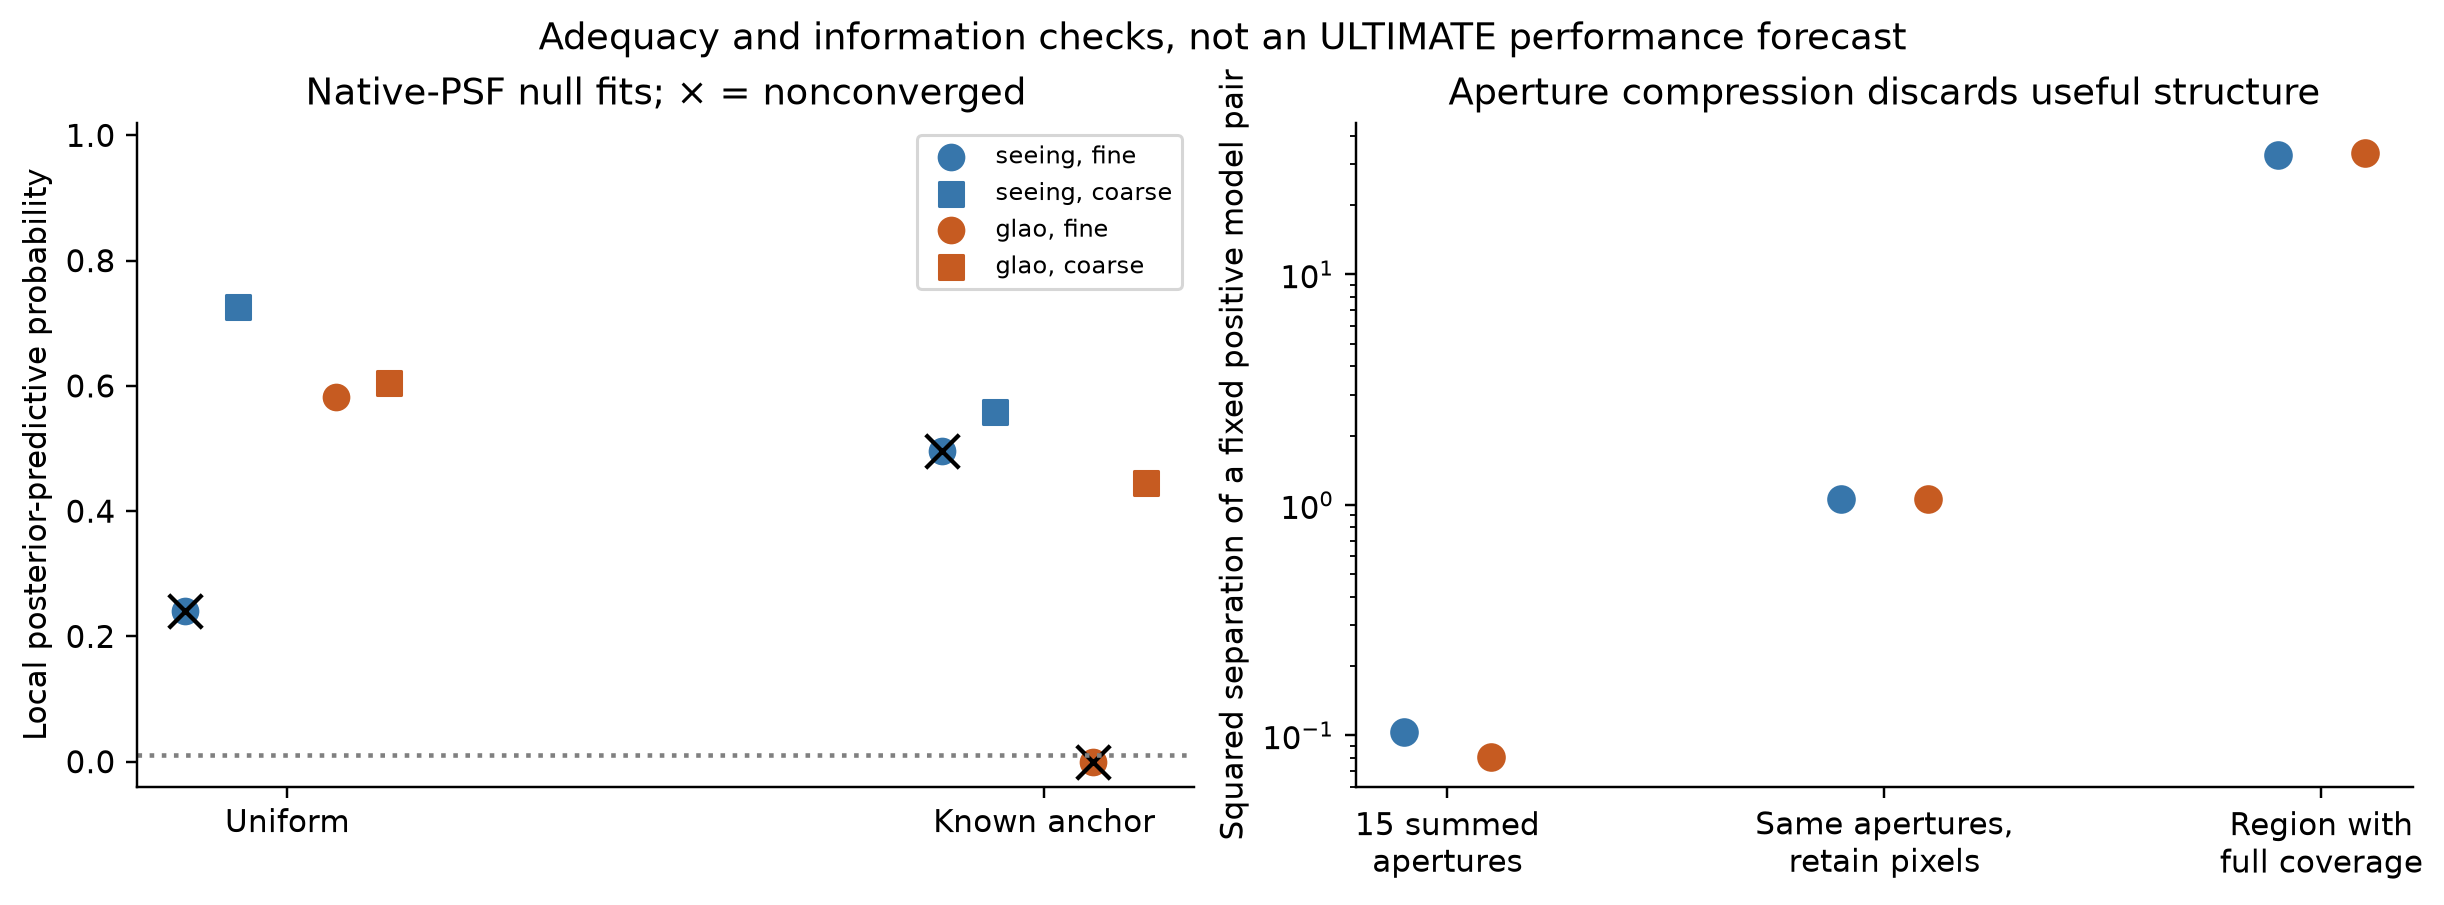

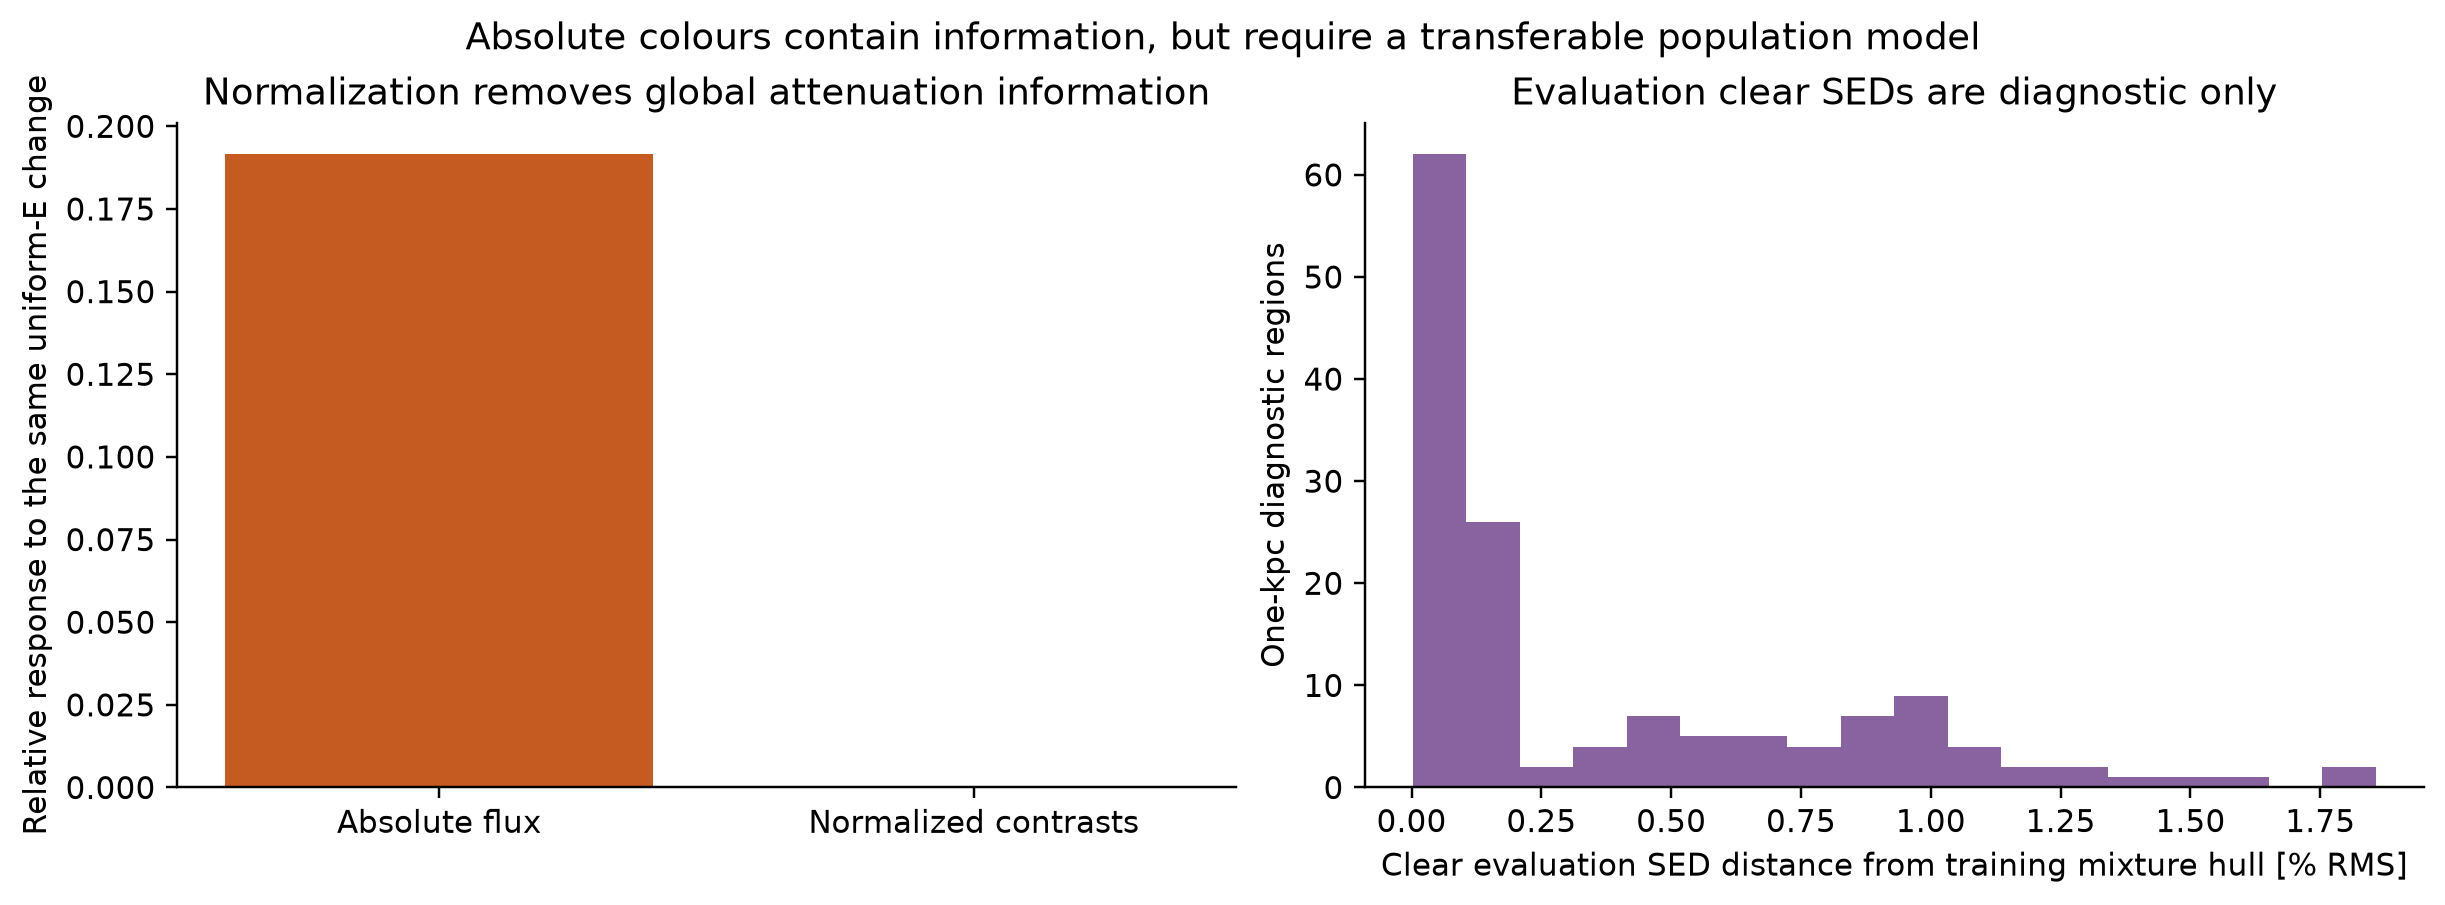

In [8]:
for path in paths[3:]:
    display(Image(filename=str(path)))


## Takeaways
NO-GO for a physical geometry claim or ML with the current pipeline. The next justified step is preserving full spatial information and independently validating the stellar SED model. This is not a demonstrated fundamental failure of all broadband imaging. Read the executed report below, including optimizer and adequacy failures.


In [9]:
display(Markdown((O/'scientific_report.md').read_text()))


# Targeted physical-model diagnosis and scientific decision

**NO-GO for a robust broadband dust-geometry claim with the current inference pipeline.** This is not proof that full optical/NIR images are fundamentally incapable of dust discrimination. Both structural model errors and information discarded by the sparse measurements remain important. No full previous grid, large Monte Carlo, download, installation, DR2 work or ML was run.

## 1. Why the98.4% false-positive failure occurred
The exact named z=.3 matched/seeing benchmark reproduces492/500 rejections (98.4%;95% CI96.9–99.3%). Its imposed log-colour direction lies in the original two population PCs to relative precision3e-16, with95% squared overlap with the dust direction. The spatial response has full rank14 for14 contrasts and reconstructs the spatial test mode to4.5e-16. **Neither a missing log-colour PC nor an insufficient number of spatial basis vectors is the dominant failure.**

The old model instead gives the wrong probability/covariance to a brightness-weighted, multiplicative population field. The same noise-free source gives a Gaussian score85.45 above the previous69.59 cutoff. Doubling population SD changes it to-22.39; adding the actual spatial population mode diagnostically changes it to-41.79; a short-correlation covariance limit gives-42.60. Those are mechanism tests, not priors adopted to force controls to pass. Null prior-predictive Q falls from286 for98 contrasts to91 when population SD doubles. Exact photometric covariance propagation agrees with explicit matrix multiplication at~1e-20.

Multiplication adds curvature: the fractional multiplier has0.43% of its norm outside the first two PCs, rising to2.56% after weighting by the actual stellar colours, with maximum residual~3%. The additive Gaussian population covariance is not the correct forward push-forward of these source fields. Dust offers a cheap, strongly aligned colour mode and absorbs the discrepancy. This is **structural statistical-model inadequacy amplified by a real population–dust degeneracy**, not evidence for variable dust.

## 2. One improved positive model, and its limits
Implemented positive luminosity surface brightness × convex mixtures of seven independent training-region DR1 source SEDs × exp[-0.4 ln10 k(lambda) E(x)]. Stellar mixture weights and attenuation are spatial fields; E is bounded0–0.6. Luminosity is nuisance, with no known stellar mass or intrinsic target normalization. The same stellar model is used under uniform and variable attenuation. Band-specific PSFs, source-photon variance,60 split reads and full aperture covariance are preserved. The adjoint projection is validated against the original renderer; analytic derivatives and nesting/positivity pass tests.

Training uses x<-4kpc only. The target clear SEDs and physical maps are never fit inputs; they appear only in counterfactual generation/post-fit coverage diagnostics. These are physically positive *empirical broadband mixtures*, not a full SPS/SFH/age-metallicity inference. Model-family recovery succeeds, but absolute-colour physical nulls fail: χ²=436.2 for the uniform DR1 source and812.1 for the known anchor, with local predictive probabilities0. Normalized-contrast null fits instead have χ²=65.3/75.6 and predictive probabilities0.339/0.202.

Absolute colours retain information: changing uniform E alters raw fluxes by19%, while normalized contrasts change only at~1e-15. Yet using those colours requires a transferable population model. Independent-template coverage, spatial population constraints and source-grid approximations are audited in `absolute_failure_isolation.csv`; a good contrast fit cannot establish that the absolute stellar SED is correct. Grid-only error is not the complete explanation: fitting a source generated exactly on the model grid still gives null residual χ²443/881. A matched-PSF, unrestricted-per-aperture mixture *coverage diagnostic only* also retains large marginal weighted residuals; it is not the adopted inference model. Source Monte Carlo uncertainty and independent SPS/domain-transfer errors are not available as validated error maps; no discrepancy floor was invented to force acceptance. No global-colour or aperture freedom was added after seeing the held-out cases just to make them pass.

## 3. Challenging held-out pilot; no large evaluation after failed gate
The failed raw physical gate prohibited a large independent evaluation or new GLAO power claim. A bounded diagnostic pilot used19 known-family calibration noise draws and independent held-out observations: one absolute-colour and three contrast draws per scene. Each fit has a fixed data-initialized null start and nested alternative start, rather than sequential noise-dependent warm starts. The statistic is **penalized MAP objective improvement**, not a Bayes factor or unpenalized profile χ². A maximum-of19 cutoff is nominal5% only conditional on exchangeable scores for that one model-family null; it does not calibrate physical population robustness. Optimizer failures and predictive adequacy are saved per draw.

New population patterns include a shifted/rotated log-PC1+PC3 gradient and patchy mixtures drawn from the full independent training sample, not just the fitted prototypes. The known anchor is a development benchmark, not relabelled blind validation. Each stellar scene has paired clear, uniform, smooth and patchy screens; original SKIRT is separate. Each scenario remains separate below. Tiny-sample intervals are deliberately wide and **cannot certify an acceptable false-positive rate or reliable power**.

| population | screen | rejections [95% CI] | null / alternative adequate |
| --- | --- | --- | --- |
| DR1 | clear | 2/3 [9.4–99.2%] | 100% / 100% |
| DR1 | patchy | 3/3 [29.2–100.0%] | 33% / 100% |
| DR1 | smooth | 3/3 [29.2–100.0%] | 0% / 0% |
| DR1 | uniform | 1/3 [0.8–90.6%] | 100% / 67% |
| SKIRT | original | 3/3 [29.2–100.0%] | 0% / 33% |
| known_anchor | clear | 3/3 [29.2–100.0%] | 0% / 100% |
| known_anchor | patchy | 3/3 [29.2–100.0%] | 0% / 67% |
| known_anchor | smooth | 3/3 [29.2–100.0%] | 0% / 100% |
| known_anchor | uniform | 3/3 [29.2–100.0%] | 33% / 67% |
| rotated_PC1_PC3 | clear | 3/3 [29.2–100.0%] | 0% / 0% |
| rotated_PC1_PC3 | patchy | 3/3 [29.2–100.0%] | 0% / 0% |
| rotated_PC1_PC3 | smooth | 3/3 [29.2–100.0%] | 0% / 0% |
| rotated_PC1_PC3 | uniform | 3/3 [29.2–100.0%] | 0% / 67% |
| training_SED_patch | clear | 3/3 [29.2–100.0%] | 67% / 0% |
| training_SED_patch | patchy | 3/3 [29.2–100.0%] | 33% / 33% |
| training_SED_patch | smooth | 3/3 [29.2–100.0%] | 0% / 0% |
| training_SED_patch | uniform | 3/3 [29.2–100.0%] | 0% / 0% |

Full absolute-colour results, optimizer flags and paired old-Gaussian diagnostics are in the CSV files. Local Laplace posterior checks are approximations; effective-dof χ² tail values are descriptive and not used as calibrated adequacy probabilities. There were42 nonconverged null fits and33 nonconverged alternative fits among68 fit pairs. They remain explicitly flagged; raw threshold crossings from those fits are not valid optimized detections. The primary physical gate remains failed, whatever individual pilot rejection counts show.

## 4. GLAO, aperture loss and identifiability
The native-resolution problem is **not resolved by the default fine-field model**. For the known stellar-only anchor, its seeing fit gives χ²62.17 and local predictive probability0.496, but does not converge; the GLAO fit gives χ²154.98 and probability0, and also does not converge. With the same1.5kpc apertures, the coarser population field converges for both seeing and GLAO, with χ²58.77/58.95 and predictive probabilities0.559/0.445. Thus more spatial flexibility did not automatically improve fitting; optimization and population regularization remain material limitations. Coarse/fine fields and3kpc apertures are adequacy sensitivity checks, not a post-hoc selection for claimed power. A classifier losing recovery with narrower PSFs is not proof of physical information loss. The previous8-percentage-point gain remains unvalidated as an instrument forecast.

A constructive positive pair demonstrates an important distinction. A stellar-mixture/morphology change of1.34 prior-standard-deviation norm can offset an E-field RMS change of0.0192 in the sparse data. Its15-aperture squared mean separation is0.103 seeing/0.081 GLAO. Even the optimal fixed-pair Gaussian test would then have only9.3%/8.7% power at5% false positives. These are conditional, optimistic known-pair bounds, not population-marginalized recovery rates.

**That degeneracy does not persist for this pair when retaining the spatial pixels.** The same evaluation rectangle gives squared separation33.13 seeing/33.66 GLAO. Thus the sparse apertures discarded discriminating information; a blanket claim of fundamental broadband non-identifiability would be unsupported. Full-pixel known-pair power saturates near100%, so this example cannot measure a useful GLAO power increment. A robust full-image model with unknown stellar populations has not been validated here.

## 5. Scientific decision and minimal next information
1. **Reliable uniform-versus-varying discrimination? No, not established.** The old catastrophic population error is diagnosed and the positive model improves contrast adequacy, but raw-colour model failure and tiny held-out counts prevent a reliable detection claim.
2. **Which variations remain ambiguous?** Dust-aligned stellar-colour gradients and positive mixtures can mimic varying attenuation in the compressed data. Global uniform attenuation is exactly unidentifiable from separately normalized bands. The present tests do not prove ambiguity in every full image or every allowed stellar population. The stellar-nuisance Jacobian locally spans the105 raw or98 contrast measurements, while regularization reduces effective fitted freedom; data-only local identification is therefore not supplied by these sparse measurements. This is not a claim about all possible full-image constraints.
3. **Robust GLAO advantage when fitting is adequate? Not demonstrated.** Conditional model-family/pixel information checks are consistent with a modest gain, but they are not a validated population-uncertain classification forecast. Failed raw fits prohibit that conclusion.
4. **What information is minimally needed next?** First retain existing image pixels or densely sampled PSF-aware spatial data—the information is already present for the constructed pair. Then validate an independent stellar SED library and spatial population model. Resolved absorption-feature/age/metallicity/SFH constraints, or bands demonstrated to constrain a direction distinct from reddening, are candidates; more continuum bands are not automatically sufficient. For the *sparse constructed pair only*, an ideal independent constraint on its coherent intrinsic g−Ks colour mode at roughly0.021mag would reach80% idealized fixed-pair power. That number is not a spectroscopic exposure requirement, general threshold or ULTIMATE forecast. The minimal real band/spectrum requirement cannot yet be established from this inadequate model.

**Recommendation: NO-GO for broadband-only dust-geometry detections or ML training with the current pipeline. GO only for targeted full-image forward-model and independent stellar-population validation.** Rejection of a screen never identifies a unique3D geometry. Only galaxy294866 is local; no galaxy-to-galaxy generalization is tested.

## Observing scope
Actual DR1 griz and2MASS J/H/Ks retain their rest-band meaning. z=.3 specifies conditional matched-rest-band degradation with fixed intrinsic size/luminosity and I_nu/(1+z)^3; no exact observer-frame K correction is invented. Rest Ks would lie near2.81µm, outside ordinary Ks coverage. Nominal-band sky/throughput/PSFs remain provisional proxies; these results are not a realizable seven-filter ULTIMATE forecast. Existing HAWK-I checks and all previous experiments are preserved.
